# Investigación Operativa — Laboratorio 0
## De una formulación matemática a una recomendación reproducible

**Clase 01 · Licenciatura en Ciencia de Datos · Universidad Austral**

### Objetivos

Al finalizar el laboratorio podrá:

1. representar un modelo lineal con la API de `scipy.optimize.linprog`;
2. interpretar el estado del solver antes de usar la solución;
3. verificar restricciones, holguras y valor objetivo;
4. comparar políticas y documentar una recomendación;
5. distinguir una solución computacional de un modelo validado.

> El caso es didáctico y simulado. Los puntos de valor no describen operaciones reales de la Universidad.

## 0. Pregunta de decisión

Un equipo analítico debe asignar su capacidad semanal entre **tableros operativos** y **modelos predictivos**. Dispone de 80 h de CPU, 60 h de GPU y 50 h de analista.

**Pregunta:** ¿cuántas unidades de cada servicio conviene realizar para maximizar el valor total, y qué recursos limitan esa decisión?

Antes de ejecutar código, complete:

- Decisor: Manager del equipo analítico
- Horizonte: Week on Week
- Variables con unidades: GPU, CPU, ANALISTA | Tableros y Modelos
- Audiencia de la recomendación: Manager del equipo analitico, C-Level
- Un supuesto que debería validarse: Asumimos venta completa de los recursos, costos fijos no influyen, etc

In [6]:
from pathlib import Path
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.optimize import linprog

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("SciPy:", scipy.__version__)

Python: 3.12.3
NumPy: 2.5.1
pandas: 3.0.5
SciPy: 1.18.0


## 1. Datos, unidades y controles

Lea el archivo `../Datos/caso_capacidad_analitica.csv`. Verifique:

- que existan dos servicios;
- que los coeficientes de recursos sean no negativos;
- que las capacidades tengan unidades compatibles con los consumos;
- que no haya valores faltantes donde el modelo necesita un coeficiente.

In [18]:
DATA = "caso_capacidad_analitica.csv"
df = pd.read_csv(DATA)
df

,servicio,valor_por_unidad,horas_cpu,horas_gpu,horas_analista
0,Tablero operativo,40.0,2,0,1
1,Modelo predictivo,100.0,1,2,1
2,capacidad_disponible,NaN,80,60,50


In [19]:
# TODO: separe las filas de servicios de la fila de capacidades.
# Construya una tabla compacta para auditar los coeficientes.

servicios = df.iloc[:2].copy()
capacidades = df.iloc[-1].copy()

print("Complete esta celda antes de continuar.")

Complete esta celda antes de continuar.


In [20]:
servicios

,servicio,valor_por_unidad,horas_cpu,horas_gpu,horas_analista
0,Tablero operativo,40.0,2,0,1
1,Modelo predictivo,100.0,1,2,1


In [21]:
capacidades

servicio            capacidad_disponible
valor_por_unidad                     NaN
horas_cpu                             80
horas_gpu                             60
horas_analista                        50
Name: 2, dtype: object

## 2. Formulación

Defina:

- $x_T$: unidades semanales de tableros operativos;
- $x_M$: unidades semanales de modelos predictivos.

El modelo es:

\begin{aligned}
\max\quad &40x_T+100x_M\\
\text{s.a.}\quad &2x_T+x_M\le80,\\
&2x_M\le60,\\
&x_T+x_M\le50,\\
&x_T,x_M\ge0.
\end{aligned}

`linprog` minimiza. Por lo tanto, para maximizar $c^Tx$ debe minimizar $-c^Tx$.

In [23]:
servicios

,servicio,valor_por_unidad,horas_cpu,horas_gpu,horas_analista
0,Tablero operativo,40.0,2,0,1
1,Modelo predictivo,100.0,1,2,1


In [ ]:
# TODO: complete los coeficientes usando el orden [x_T, x_M].
c_max = np.array([40, 100])
A_ub = np.array([
    [2, 1],  # CPU
    [0, 2],  # GPU
    [1, 1],  # analista
])
b_ub = np.array([80, 60, 50])
bounds = [(0, None), (0, None)]


### Control previo

Antes de llamar al solver, explique en una oración qué representa cada fila de `A_ub` y qué unidad tiene el producto matricial `A_ub @ x`.

* c_max = Funcion objetivo
* A_ub son las restricciones (coeficientes)
* b_ub son el resultado de cada restriccion
* Las unidades son horas

In [28]:
# TODO: quite el comentario cuando los coeficientes estén completos.
resultado = linprog(c=-c_max, A_ub=A_ub, b_ub=b_ub,
                     bounds=bounds, method="highs")
print(resultado.message)

Optimization terminated successfully. (HiGHS Status 7: Optimal)


In [41]:
resultado

        message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
        success: True
         status: 0
            fun: -3800.0
              x: [ 2.000e+01  3.000e+01]
            nit: 2
          lower:  residual: [ 2.000e+01  3.000e+01]
                 marginals: [ 0.000e+00  0.000e+00]
          upper:  residual: [       inf        inf]
                 marginals: [ 0.000e+00  0.000e+00]
          eqlin:  residual: []
                 marginals: []
        ineqlin:  residual: [ 1.000e+01  0.000e+00  0.000e+00]
                 marginals: [-0.000e+00 -3.000e+01 -4.000e+01]
 mip_node_count: 0
 mip_dual_bound: 0.0
        mip_gap: 0.0

In [42]:
resultado.x

array([20., 30.])

In [66]:
from scipy.optimize import linprog
from time import perf_counter

for metodo in ["highs", "highs-ds", "highs-ipm"]:
    inicio = perf_counter()

    resultado = linprog(
        c=-c_max,
        A_ub=A_ub,
        b_ub=b_ub,
        bounds=bounds,
        method=metodo
    )

    tiempo = perf_counter() - inicio

    print(f"\nMethod: {metodo}")
    print("Success:", resultado.success)
    print("Status:", resultado.status)
    print("Iterations:", resultado.nit)
    print("Time:", tiempo)
    print("Maximum:", -resultado.fun if resultado.success else None)


Method: highs
Success: True
Status: 0
Iterations: 2
Time: 0.0013810509990435094
Maximum: 3800.0

Method: highs-ds
Success: True
Status: 0
Iterations: 2
Time: 0.00097915100013779
Maximum: 3800.0

Method: highs-ipm
Success: True
Status: 0
Iterations: 5
Time: 0.0009870069989119656
Maximum: 3800.0


## 3. Estado antes que solución

Registre:

- `resultado.success`;
- `resultado.status`;
- `resultado.message`;
- el método utilizado.

No interprete `resultado.x` si el estado no permite hacerlo.

In [45]:
# TODO: construya un resumen explícito del estado del solver.
estado = {
     "success": resultado.success,
     "status": resultado.status,
     "message": resultado.message,
}

estado

{'success': True,
 'status': 0,
 'message': 'Optimization terminated successfully. (HiGHS Status 7: Optimal)'}

## 4. Verificación automática

Implemente una función que reciba una solución y compruebe:

1. no negatividad;
2. consumo de cada recurso;
3. violación máxima con tolerancia;
4. valor objetivo recalculado;
5. holguras.

In [52]:
def verificar_solucion(x, A, b, c, tol=1e-7):
    'Devuelva un diccionario con controles de factibilidad y objetivo.'
    # Verificar no negatividad
    if (x < -tol).any():
        print("Solución contiene valores negativos")
        return {"success": False, "message": "Solución contiene valores negativos"}

    # Verificar consumo de recursos
    consumo = A @ x
    if (consumo - b > tol).any():
        print("Consumo de recursos excede la capacidad")
        return {"success": False, "message": "Consumo de recursos excede la capacidad"}

    # Verificar valor objetivo
    valor_objetivo = c @ x
    if valor_objetivo < -tol:
        print("Valor objetivo es negativo")
        return {"success": False, "message": "Valor objetivo es negativo"}

    # Verificar holguras
    holguras = b - consumo
    if (holguras < -tol).any():
        print("Holguras negativas")
        return {"success": False, "message": "Holguras negativas"}

    return {"success": True, "message": "Solución factible"}

In [73]:
b_ub

array([80, 60, 50])

In [76]:
A_ub @ resultado.x

array([70., 60., 50.])

In [ ]:
# TODO: use la función sobre la solución del solver.
verificacion = verificar_solucion(resultado.x, A_ub, b_ub, c_max)
verificacion

{'success': True, 'message': 'Solución factible'}

## 5. Interpretación

Construya una tabla con:

- variable;
- valor óptimo;
- unidad;
- interpretación operacional.

Luego identifique qué restricciones están activas usando una tolerancia explícita.

In [57]:
# TODO: tabla de decisión y tabla de recursos.

pd.DataFrame({
    "variable": ["x_T", "x_M"],
    "valor óptimo": [resultado.x[0], resultado.x[1]],
    "unidad": ["unidades", "unidades"],
    "interpretación operacional": ["Tableros operativos", "Modelos predictivos"]
})


,variable,valor óptimo,unidad,interpretación operacional
0,x_T,20.0,unidades,Tableros operativos
1,x_M,30.0,unidades,Modelos predictivos


In [71]:
servicios

,servicio,valor_por_unidad,horas_cpu,horas_gpu,horas_analista
0,Tablero operativo,40.0,2,0,1
1,Modelo predictivo,100.0,1,2,1


## 6. Visualización del conjunto factible

Grafique las tres fronteras, sombree la región factible y marque la solución encontrada. El gráfico es una ayuda de validación: debe usar las mismas unidades y coeficientes que la formulación.

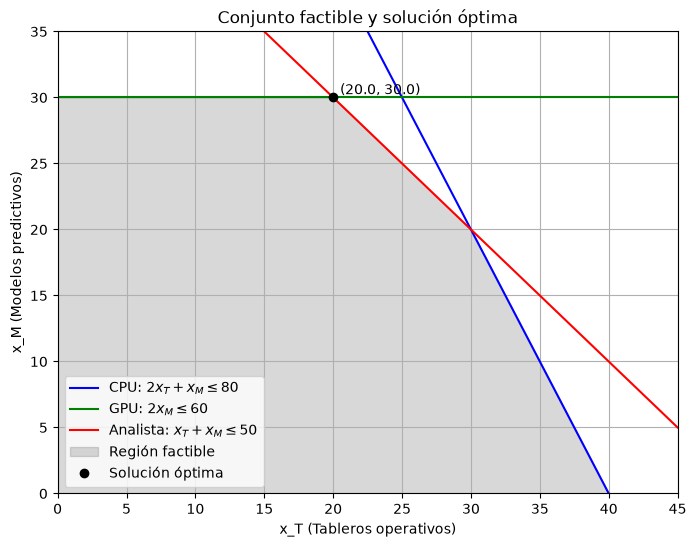

In [72]:
# TODO: construya la visualización para 0 <= x_T <= 45.

import matplotlib.pyplot as plt
import numpy as np

# Asumiendo que las variables de decisión son x_T (Tablero operativo) y x_M (Modelo predictivo)
# Variables:
# x = [x_T, x_M]
# Restricciones de capacidad:
# 2 x_T + 1 x_M <= 80  (horas_cpu)
# 0 x_T + 2 x_M <= 60  (horas_gpu)
# 1 x_T + 1 x_M <= 50  (horas_analista)
# Además: x_T >= 0, x_M >= 0

x_T = np.linspace(0, 45, 300)

# Calculamos las fronteras de las restricciones
# frontera_cpu: 2x_T + x_M = 80 -> x_M = 80 - 2x_T
frontera_cpu = 80 - 2*x_T
# frontera_gpu: 2x_M = 60 -> x_M = 30 (constante)
frontera_gpu = np.full_like(x_T, 30)
# frontera_analista: x_T + x_M = 50 -> x_M = 50 - x_T
frontera_analista = 50 - x_T

# Restringimos para mantener valores admisibles (x_M >= 0)
def no_neg(array):
    return np.maximum(array, 0)

plt.figure(figsize=(8, 6))

# Dibujamos las restricciones
plt.plot(x_T, frontera_cpu, label='CPU: $2x_T + x_M \\leq 80$', color='blue')
plt.plot(x_T, frontera_gpu, label='GPU: $2x_M \\leq 60$', color='green')
plt.plot(x_T, frontera_analista, label='Analista: $x_T + x_M \\leq 50$', color='red')

# Sombreamos la región factible
# Región factible: para cada x_T, el valor mínimo de restricción
x_M_top = np.minimum.reduce([
    frontera_cpu, frontera_gpu, frontera_analista
])
x_M_top = no_neg(x_M_top)

plt.fill_between(x_T, 0, x_M_top, where=(x_M_top >= 0), color='gray', alpha=0.3, label='Región factible')

# Marcar la solución óptima encontrada
xT_opt, xM_opt = resultado.x
plt.plot([xT_opt], [xM_opt], 'ko', label='Solución óptima')
plt.text(xT_opt + 0.5, xM_opt, f'({xT_opt:.1f}, {xM_opt:.1f})', verticalalignment='bottom')

plt.xlim(0, 45)
plt.ylim(0, 35)
plt.xlabel('x_T (Tableros operativos)')
plt.ylabel('x_M (Modelos predictivos)')
plt.title('Conjunto factible y solución óptima')
plt.legend()
plt.grid(True)
plt.show()

## 7. Comparación de políticas

Evalúe, sin volver a optimizar, las políticas:

- A: $(20,20)$;
- B: $(40,0)$;
- C: $(25,30)$;
- D: $(20,30)$.

Para cada una informe factibilidad, valor y recursos violados. Explique por qué una política con valor aparente alto puede ser inadmisible.

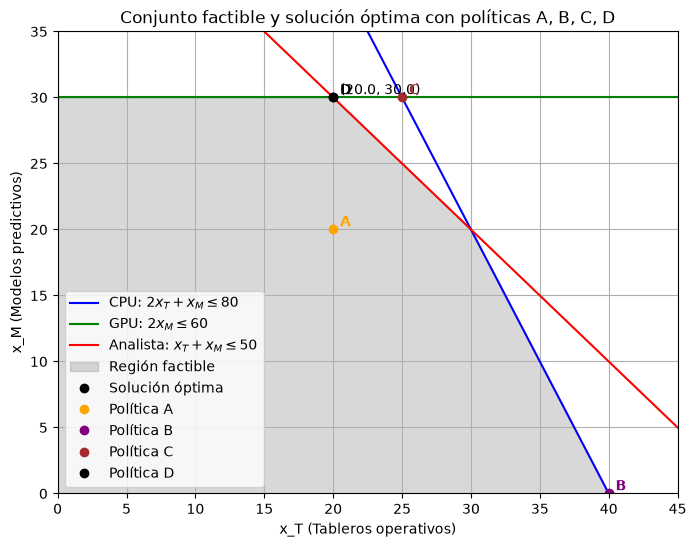

In [77]:
politicas = {
    "A": np.array([20.0, 20.0]),
    "B": np.array([40.0, 0.0]),
    "C": np.array([25.0, 30.0]),
    "D": np.array([20.0, 30.0]),
}

import matplotlib.pyplot as plt
import numpy as np

# Asumiendo que las variables de decisión son x_T (Tablero operativo) y x_M (Modelo predictivo)

x_T = np.linspace(0, 45, 300)

# Calculamos las fronteras de las restricciones
frontera_cpu = 80 - 2*x_T
frontera_gpu = np.full_like(x_T, 30)
frontera_analista = 50 - x_T

def no_neg(array):
    return np.maximum(array, 0)

plt.figure(figsize=(8, 6))

# Dibujamos las restricciones
plt.plot(x_T, frontera_cpu, label='CPU: $2x_T + x_M \\leq 80$', color='blue')
plt.plot(x_T, frontera_gpu, label='GPU: $2x_M \\leq 60$', color='green')
plt.plot(x_T, frontera_analista, label='Analista: $x_T + x_M \\leq 50$', color='red')

# Sombreamos la región factible
x_M_top = np.minimum.reduce([
    frontera_cpu, frontera_gpu, frontera_analista
])
x_M_top = no_neg(x_M_top)

plt.fill_between(x_T, 0, x_M_top, where=(x_M_top >= 0), color='gray', alpha=0.3, label='Región factible')

# Marcar la solución óptima encontrada
xT_opt, xM_opt = resultado.x
plt.plot([xT_opt], [xM_opt], 'ko', label='Solución óptima')
plt.text(xT_opt + 0.5, xM_opt, f'({xT_opt:.1f}, {xM_opt:.1f})', verticalalignment='bottom')

# Agregar los puntos de las políticas A, B, C, D
colores_politicas = {"A": "orange", "B": "purple", "C": "brown", "D": "black"}
for nombre, punto in politicas.items():
    plt.plot([punto[0]], [punto[1]], 'o', color=colores_politicas[nombre], label=f'Política {nombre}')
    plt.text(punto[0] + 0.5, punto[1], f'{nombre}', color=colores_politicas[nombre], fontweight='bold', verticalalignment='bottom')

plt.xlim(0, 45)
plt.ylim(0, 35)
plt.xlabel('x_T (Tableros operativos)')
plt.ylabel('x_M (Modelos predictivos)')
plt.title('Conjunto factible y solución óptima con políticas A, B, C, D')
plt.legend()
plt.grid(True)
plt.show()

### Respuesta
* A Es factible pero no optima
* B no es factible
* C y D es factible pero solo D es optima

## 8. Experimento: una restricción inactiva

Aumente la capacidad de CPU de 80 a 90 horas y resuelva nuevamente.

1. ¿Cambia la decisión?
2. ¿Cambia el valor óptimo?
3. ¿Cómo se relaciona el resultado con la holgura del modelo base?

Después disminuya CPU a 65 horas y repita. Documente los dos escenarios en una tabla.

In [ ]:
# TODO: función resolver(cap_cpu) y tabla para CPU = 65, 80 y 90.

c_max = np.array([40, 100])
A_ub = np.array([
    [2, 1],  # CPU
    [0, 2],  # GPU
    [1, 1],  # analista
])
b_ub = np.array([90, 60, 50])
bounds = [(0, None), (0, None)]

# TODO: quite el comentario cuando los coeficientes estén completos.
resultado = linprog(c=-c_max, A_ub=A_ub, b_ub=b_ub,
                     bounds=bounds, method="highs")

In [86]:
resultado

        message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
        success: True
         status: 0
            fun: -3800.0
              x: [ 2.000e+01  3.000e+01]
            nit: 2
          lower:  residual: [ 2.000e+01  3.000e+01]
                 marginals: [ 0.000e+00  0.000e+00]
          upper:  residual: [       inf        inf]
                 marginals: [ 0.000e+00  0.000e+00]
          eqlin:  residual: []
                 marginals: []
        ineqlin:  residual: [ 2.000e+01  0.000e+00  0.000e+00]
                 marginals: [-0.000e+00 -3.000e+01 -4.000e+01]
 mip_node_count: 0
 mip_dual_bound: 0.0
        mip_gap: 0.0

In [87]:
resultado.x

array([20., 30.])

<hr>

In [88]:
# TODO: función resolver(cap_cpu) y tabla para CPU = 65, 80 y 90.
c_max = np.array([40, 100])
A_ub = np.array([
    [2, 1],  # CPU
    [0, 2],  # GPU
    [1, 1],  # analista
])
b_ub = np.array([65, 60, 50])
bounds = [(0, None), (0, None)]

# TODO: quite el comentario cuando los coeficientes estén completos.
resultado = linprog(c=-c_max, A_ub=A_ub, b_ub=b_ub,
                     bounds=bounds, method="highs")

In [90]:
resultado.x

array([17.5, 30. ])

<hr>

1. ¿Cambia la decisión?
* Solo cambia bajo el segundo escenario

2. ¿Cambia el valor óptimo?
* En el segundo caso si

3. ¿Cómo se relaciona el resultado con la holgura del modelo base?
* Bajo el primer caso se aprovecha la holugura de 10 por lo que no cambia

## 9. Recomendación ejecutiva

Escriba entre 120 y 180 palabras. Debe incluir:

- decisión recomendada y horizonte;
- valor esperado con unidad;
- recursos activos y holguras;
- supuesto crítico;
- límite del modelo;
- dato o experimento necesario antes de implementar.

### Recomendación

_Escriba aquí._

## 10. Exit ticket individual

1. ¿Qué diferencia hay entre `resultado.success` y haber validado el modelo?
2. ¿Qué error detectaría el control dimensional que el solver no detecta?
3. Si los servicios deben entregarse en unidades completas, ¿qué parte del modelo debe cambiar?

In [91]:
resultado.success

True